<a href="https://colab.research.google.com/github/kalilafambro/beginning--bioinformatics/blob/main/notebooks/Fusarium_EF1a_BLAST_vs_kmer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fusarium species-complex identification: BLAST vs. a k-mer classifier (EF-1α)
**Scope :** one locus (EF-1α), two methods (BLAST top-hit and one k-mer logistic-regression model), study-level train/test split, and a *limited* truncation experiment (100% / 75% / 50% length). All degraded copies of a sequence stay together: they share a `parent_id`, are never split apart, and uncertainty is a bootstrap over **original sequences**.

Run top to bottom in Google Colab. Set `DEMO = True` first to check the whole pipeline on synthetic data (no NCBI needed), then set it to `False` for real data.

In [1]:
!apt-get -qq install -y ncbi-blast+ > /dev/null
!pip -q install biopython scikit-learn pandas matplotlib

In [2]:
import os, re, time, subprocess, platform
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ---------------- CONFIG ----------------
DEMO = False                 # True = synthetic data to test the pipeline; False = real GenBank data
EMAIL = "kxf2833@mavs.uta.edu"   # NCBI requires an email
NCBI_API_KEY = None         # optional; speeds up downloads
SEED = 42
MAX_RECORDS = 1500
COMPLEXES = ["FSSC", "FOSC", "GFSC", "FIESC", "FDSC"]
LENGTHS = [1.0, 0.75, 0.5]  # fraction of original length kept (limited truncation experiment)
K = 6                       # k-mer size (single value to start)
N_BOOT = 1000
TEST_SIZE = 0.30
MIN_LEN, MAX_LEN = 400, 1100
# ----------------------------------------
rng = np.random.default_rng(SEED)
os.makedirs("data", exist_ok=True); os.makedirs("results", exist_ok=True)

## 1. Species name → complex labels
Labels come from the GenBank organism name, so they inherit database labeling errors (a limitation to state in the report; O'Donnell et al. 2010, p. 3713, warn that GenBank contains misnamed *Fusarium* sequences). Check/extend this map against O'Donnell et al. (2010) Table 1 (pp. 3710–3711). Records that do not match (e.g., "Fusarium sp.") are dropped.

In [3]:
COMPLEX_MAP = {
    "FSSC":  ["fusarium solani", "neocosmospora", "fusarium falciforme", "fusarium keratoplasticum",
              "fusarium petroliphilum", "fusarium lichenicola"],
    "FOSC":  ["fusarium oxysporum"],
    "GFSC":  ["fusarium verticillioides", "fusarium fujikuroi", "fusarium proliferatum", "fusarium subglutinans",
              "fusarium thapsinum", "fusarium nygamai", "fusarium sacchari", "fusarium ananatum",
              "fusarium acutatum", "fusarium napiforme"],
    "FIESC": ["fusarium incarnatum", "fusarium equiseti", "fusarium lacertarum"],
    "FDSC":  ["fusarium dimerum", "fusarium delphinoides", "fusarium penzigii"],
}
def label_from_organism(name):
    n = name.lower()
    if " sp." in n and not any(s in n for s in ["f. sp.", "f.sp."]):
        return None
    for cx, keys in COMPLEX_MAP.items():
        if any(k in n for k in keys):
            return cx
    return None

## 2. Get the data (GenBank EF-1α, or synthetic demo)

In [4]:
def make_demo_df(n_per_complex=60, n_studies=12):
    bases = np.array(list("ACGT"))
    def mutate(s, rate):
        s = np.array(list(s)); m = rng.random(len(s)) < rate
        s[m] = rng.choice(bases, m.sum()); return "".join(s)
    rows, acc = [], 0
    root = "".join(rng.choice(bases, 650))
    for cx in COMPLEXES:
        cx_seq = mutate(root, 0.12)
        for sp in range(3):
            sp_seq = mutate(cx_seq, 0.04)
            for _ in range(n_per_complex // 3):
                acc += 1
                rows.append(dict(accession=f"DEMO{acc:05d}.1", organism=f"Fusarium {cx.lower()}_{sp}",
                                 complex=cx, study=f"study_{rng.integers(n_studies)}",
                                 seq=mutate(sp_seq, 0.005)))
    return pd.DataFrame(rows)

def download_genbank():
    import io, socket
    from Bio import Entrez, SeqIO
    socket.setdefaulttimeout(60)               # a stalled request errors out instead of hanging
    Entrez.email = EMAIL
    if NCBI_API_KEY: Entrez.api_key = NCBI_API_KEY
    term = ('Fusarium[Organism] AND (tef1[Gene] OR "translation elongation factor 1-alpha"[Title] '
            'OR "EF-1 alpha"[Title]) AND %d:%d[SLEN]' % (MIN_LEN, MAX_LEN))
    h = Entrez.esearch(db="nucleotide", term=term, retmax=MAX_RECORDS); res = Entrez.read(h); h.close()
    ids = res["IdList"]
    print("GenBank hits:", res["Count"], "| downloading:", len(ids), flush=True)
    rows, skipped, BATCH = [], 0, 100
    for i in range(0, len(ids), BATCH):
        batch = ids[i:i + BATCH]
        for attempt in range(4):
            try:
                h = Entrez.efetch(db="nucleotide", id=",".join(batch), rettype="gb", retmode="text")
                text = h.read(); h.close(); break
            except Exception as e:
                print("  retry", attempt + 1, "after error:", e, flush=True); time.sleep(3 * (attempt + 1))
        else:
            print("  skipped batch starting at", i, flush=True); continue
        for rec in SeqIO.parse(io.StringIO(text), "genbank"):
            try:
                seq = str(rec.seq).upper()      # raises an error for records with no sequence attached
            except Exception:
                skipped += 1; continue
            refs = rec.annotations.get("references", [])
            study = (refs[0].authors + " | " + refs[0].title) if refs else "unknown"
            rows.append(dict(accession=rec.id, organism=rec.annotations.get("organism", ""),
                             study=study, seq=seq))
        print(f"  {min(i + BATCH, len(ids))}/{len(ids)} records", flush=True)
        time.sleep(0.5)
    print("records skipped (no sequence content):", skipped)
    return pd.DataFrame(rows)

if DEMO:
    raw = make_demo_df()
else:
    if os.path.exists("data/raw_ef1a.csv"):
        raw = pd.read_csv("data/raw_ef1a.csv")
    else:
        raw = download_genbank(); raw.to_csv("data/raw_ef1a.csv", index=False)
    raw["complex"] = raw["organism"].map(label_from_organism)
print(len(raw), "raw records")

GenBank hits: 28756 | downloading: 1500
  100/1500 records
  200/1500 records
  300/1500 records
  400/1500 records
  500/1500 records
  600/1500 records
  700/1500 records
  800/1500 records
  900/1500 records
  1000/1500 records
  1100/1500 records
  1200/1500 records
  1300/1500 records
  1400/1500 records
  1500/1500 records
records skipped (no sequence content): 44
1456 raw records


## 3. Clean and curate

In [5]:
df = raw.dropna(subset=["complex"]).copy()
df = df[df["complex"].isin(COMPLEXES)]
df["seq"] = df["seq"].str.upper()
df = df[df["seq"].str.fullmatch(r"[ACGT]+")]                      # drop sequences with ambiguity codes
df = df[df["seq"].str.len().between(MIN_LEN, MAX_LEN)]
df = df.drop_duplicates(subset=["study", "complex", "seq"])         # remove same-study duplicates
df = df.reset_index(drop=True)
df["parent_id"] = df["accession"]
df["length"] = df["seq"].str.len()
print(df.groupby("complex").agg(n=("accession", "size"), studies=("study", "nunique"),
                                median_len=("length", "median")))
df.drop(columns="seq").to_csv("results/curated_metadata.csv", index=False)

           n  studies  median_len
complex                          
FDSC       5        2       625.0
FIESC     21       12       678.0
FOSC     128       44       673.5
FSSC      79       36       684.0
GFSC     130       41       677.0


## 4. Split by study (no study in both train and test)
This is the "independent test set." Check the printed counts: every complex needs enough sequences in both train and test.

In [6]:
# --- diagnostics: how much data does each complex have, and from how many studies? ---
summary = df.groupby("complex").agg(n=("accession", "size"), studies=("study", "nunique"),
                                    top_study_share=("study", lambda s: round(s.value_counts(normalize=True).iloc[0], 2)))
print(summary)

# keep only complexes with enough data to appear in BOTH train and test
MIN_SEQS, MIN_STUDIES = 15, 2
keep = [c for c in COMPLEXES if c in summary.index and summary.loc[c, "n"] >= MIN_SEQS and summary.loc[c, "studies"] >= MIN_STUDIES]
print("keeping:", keep, "| dropping:", [c for c in COMPLEXES if c not in keep])
COMPLEXES = keep
df = df[df["complex"].isin(COMPLEXES)].reset_index(drop=True)

from sklearn.model_selection import GroupShuffleSplit
def find_split(df, min_train=8, min_test=3, tries=2000):
    best = None
    for s in range(tries):
        gss = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=SEED + s)
        tr, te = next(gss.split(df, groups=df["study"]))
        ctr = df.iloc[tr]["complex"].value_counts(); cte = df.iloc[te]["complex"].value_counts()
        score = min(min(ctr.get(c, 0) / min_train, cte.get(c, 0) / min_test) for c in COMPLEXES)
        if best is None or score > best[0]:
            best = (score, tr, te, SEED + s)
        if score >= 1:
            break
    if best[0] < 1:
        print("WARNING: no split met the minimums; using the best available one (score %.2f)" % best[0])
    return best[1], best[2], best[3]

tr_idx, te_idx, used_seed = find_split(df)
train, test = df.iloc[tr_idx].reset_index(drop=True), df.iloc[te_idx].reset_index(drop=True)
print("split seed:", used_seed)
counts = pd.concat([train["complex"].value_counts().rename("train"),
                    test["complex"].value_counts().rename("test")], axis=1).fillna(0).astype(int)
print(counts)
missing = [c for c in COMPLEXES if counts.loc[c, "train"] == 0 or counts.loc[c, "test"] == 0]
if missing:
    print("PROBLEM: these complexes are missing from train or test:", missing, "-> remove them from COMPLEXES and re-run from here")

           n  studies  top_study_share
complex                               
FDSC       5        2             0.80
FIESC     21       12             0.33
FOSC     128       44             0.15
FSSC      79       36             0.13
GFSC     130       41             0.22
keeping: ['FSSC', 'FOSC', 'GFSC', 'FIESC'] | dropping: ['FDSC']
split seed: 42
         train  test
complex             
GFSC        99    31
FOSC        64    64
FSSC        57    22
FIESC       15     6


## 5. Build the evaluation set (each test sequence + truncated copies, kept together by `parent_id`)

In [7]:
def window(seq, frac):
    if frac >= 1: return seq
    L = int(len(seq) * frac); start = int(rng.integers(0, len(seq) - L + 1)); return seq[start:start + L]

ev_rows = []
for _, r in test.iterrows():
    for f in LENGTHS:
        ev_rows.append(dict(parent_id=r["parent_id"], frac=f, true=r["complex"], seq=window(r["seq"], f)))
ev = pd.DataFrame(ev_rows)
ev["qid"] = ev["parent_id"] + "|" + ev["frac"].astype(str)
print(ev.groupby("frac").size())

frac
0.50    123
0.75    123
1.00    123
dtype: int64


## 6. Method A: BLAST top hit
The database contains **training sequences only**. Ties between complexes at the top bitscore are labelled `ambiguous`, and no hit is `nohit`; both count as wrong.

In [8]:
def write_fasta(path, ids, seqs):
    with open(path, "w") as fh:
        for i, s in zip(ids, seqs): fh.write(f">{i}\n{s}\n")

write_fasta("data/train.fasta", train["accession"], train["seq"])
subprocess.run("makeblastdb -in data/train.fasta -dbtype nucl -out data/train_db", shell=True, check=True,
               stdout=subprocess.DEVNULL)
write_fasta("data/query.fasta", ev["qid"], ev["seq"])
subprocess.run("blastn -task blastn -query data/query.fasta -db data/train_db -evalue 1e-5 "
               "-max_target_seqs 1000 -outfmt '6 qseqid sseqid pident length bitscore evalue' "
               "-out data/blast.tsv", shell=True, check=True)
bl = pd.read_csv("data/blast.tsv", sep="\t", names=["qid", "sid", "pident", "length", "bitscore", "evalue"])
cx_of = dict(zip(train["accession"], train["complex"]))
bl["complex"] = bl["sid"].map(cx_of)

def blast_call(g):
    top = g[g["bitscore"] >= g["bitscore"].max() - 1e-9]
    cs = set(top["complex"])
    return pd.Series({"blast_pred": cs.pop() if len(cs) == 1 else "ambiguous", "top_pident": top["pident"].max()})
calls = bl.groupby("qid").apply(blast_call)
ev = ev.merge(calls, left_on="qid", right_index=True, how="left")
ev["blast_pred"] = ev["blast_pred"].fillna("nohit")
print(ev["blast_pred"].value_counts().head(10))

blast_pred
FOSC     187
GFSC      92
FSSC      66
FIESC     22
nohit      2
Name: count, dtype: int64


/tmp/ipykernel_8248/3817197316.py:20: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  calls = bl.groupby("qid").apply(blast_call)


## 7. Method B: k-mer frequencies + logistic regression
Vectorizer, normalization, and the regularization strength `C` are all fit/tuned on training data only (grouped CV by study inside the training set).

In [9]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.preprocessing import Normalizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold, GridSearchCV

pipe = make_pipeline(CountVectorizer(analyzer="char", ngram_range=(K, K), lowercase=False),
                     Normalizer(norm="l2"),
                     LogisticRegression(max_iter=3000, class_weight="balanced"))
n_splits = min(5, train["study"].nunique())
gs = GridSearchCV(pipe, {"logisticregression__C": [1, 10, 100]}, scoring="f1_macro",
                  cv=GroupKFold(n_splits=n_splits))
gs.fit(train["seq"], train["complex"], groups=train["study"])
print("best C:", gs.best_params_, "| grouped-CV macro-F1: %.3f" % gs.best_score_)
ev["kmer_pred"] = gs.predict(ev["seq"])

best C: {'logisticregression__C': 1} | grouped-CV macro-F1: 0.930


## 8. Metrics with uncertainty at the original-sequence level
Bootstrap resamples **parent sequences** (all of a parent's truncated copies move together). The same resample is used for both methods, so the BLAST − k-mer difference is paired.

In [10]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
parents = ev["parent_id"].unique()
def mat(col):  # rows = parents, cols = LENGTHS
    return np.vstack([[ev[(ev.parent_id == p) & (ev.frac == f)][col].iloc[0] for f in LENGTHS] for p in parents])
Y, PB, PK = mat("true"), mat("blast_pred"), mat("kmer_pred")
labels = [c for c in COMPLEXES if c in set(Y[:, 0])]

def metrics(y, p):
    return accuracy_score(y, p), f1_score(y, p, labels=labels, average="macro", zero_division=0)

point = {(m, f): metrics(Y[:, j], P[:, j]) for m, P in [("BLAST", PB), ("k-mer LR", PK)] for j, f in enumerate(LENGTHS)}
boot = {k: [] for k in point}; diff = {f: [] for f in LENGTHS}
for _ in range(N_BOOT):
    b = rng.integers(0, len(parents), len(parents))
    for j, f in enumerate(LENGTHS):
        ab = metrics(Y[b, j], PB[b, j]); ak = metrics(Y[b, j], PK[b, j])
        boot[("BLAST", f)].append(ab); boot[("k-mer LR", f)].append(ak); diff[f].append(ak[0] - ab[0])

rows = []
for (m, f), (acc, f1) in point.items():
    B = np.array(boot[(m, f)])
    rows.append(dict(method=m, length_kept=f, n_parents=len(parents), accuracy=acc,
                     acc_lo=np.percentile(B[:, 0], 2.5), acc_hi=np.percentile(B[:, 0], 97.5),
                     macro_f1=f1, f1_lo=np.percentile(B[:, 1], 2.5), f1_hi=np.percentile(B[:, 1], 97.5)))
res = pd.DataFrame(rows).round(3); res.to_csv("results/metrics.csv", index=False)
print(res.to_string(index=False))
print("\nPaired accuracy difference (k-mer - BLAST), 95% bootstrap CI:")
for f in LENGTHS:
    d = np.array(diff[f]); print(f"  {int(f*100)}% length: {np.mean(d):+.3f} [{np.percentile(d,2.5):+.3f}, {np.percentile(d,97.5):+.3f}]")

  method  length_kept  n_parents  accuracy  acc_lo  acc_hi  macro_f1  f1_lo  f1_hi
   BLAST         1.00        123     0.919   0.870   0.967     0.911  0.826  0.965
   BLAST         0.75        123     0.951   0.911   0.984     0.920  0.818  0.980
   BLAST         0.50        123     0.943   0.902   0.984     0.915  0.812  0.978
k-mer LR         1.00        123     0.935   0.886   0.976     0.919  0.807  0.978
k-mer LR         0.75        123     0.911   0.854   0.959     0.902  0.788  0.965
k-mer LR         0.50        123     0.919   0.862   0.967     0.908  0.795  0.970

Paired accuracy difference (k-mer - BLAST), 95% bootstrap CI:
  100% length: +0.018 [-0.033, +0.065]
  75% length: -0.039 [-0.081, +0.000]
  50% length: -0.024 [-0.057, +0.008]


## 9. Figures

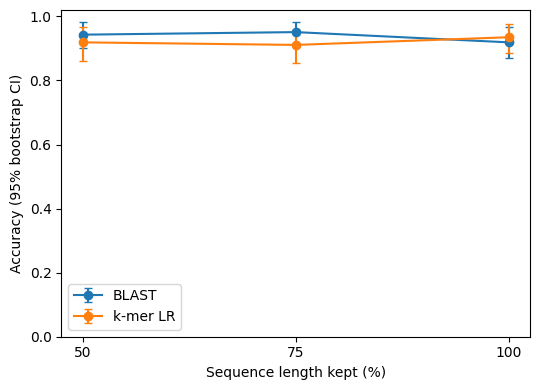

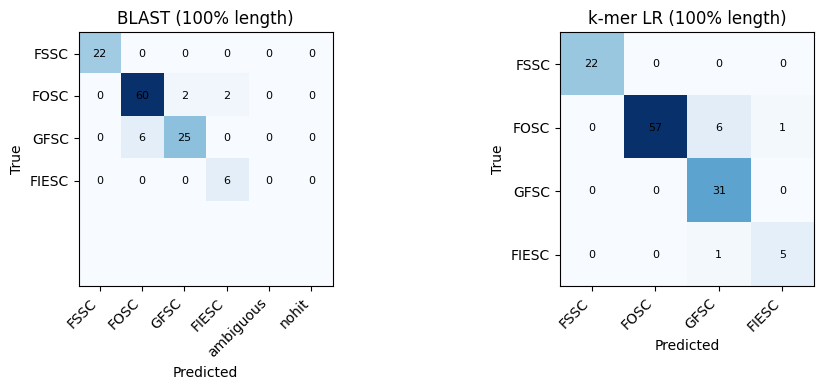

In [11]:
fig, ax = plt.subplots(figsize=(5.5, 4))
for m in ["BLAST", "k-mer LR"]:
    s = res[res.method == m].sort_values("length_kept")
    ax.errorbar(s.length_kept * 100, s.accuracy, yerr=[s.accuracy - s.acc_lo, s.acc_hi - s.accuracy],
                marker="o", capsize=3, label=m)
ax.set_xlabel("Sequence length kept (%)"); ax.set_ylabel("Accuracy (95% bootstrap CI)")
ax.set_xticks([x * 100 for x in LENGTHS]); ax.legend(); ax.set_ylim(0, 1.02)
plt.tight_layout(); plt.savefig("results/accuracy_vs_length.png", dpi=200); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (m, P) in zip(axes, [("BLAST", PB), ("k-mer LR", PK)]):
    cl = labels + ["ambiguous", "nohit"] if m == "BLAST" else labels
    cm = confusion_matrix(Y[:, 0], P[:, 0], labels=cl)
    ax.imshow(cm, cmap="Blues"); ax.set_title(f"{m} (100% length)")
    ax.set_xticks(range(len(cl))); ax.set_xticklabels(cl, rotation=45, ha="right")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(len(labels)):
        for j in range(len(cl)): ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
plt.tight_layout(); plt.savefig("results/confusion_matrices.png", dpi=200); plt.show()

## 10. Similarity check: does accuracy depend on how close the test sequence is to the training set?
Uses BLAST % identity of each full-length test sequence to its best training hit (a check for leakage through near-identical alleles).

In [12]:
full = ev[ev.frac == 1.0].copy()
full["bin"] = pd.cut(full["top_pident"], [0, 97, 99, 100.01], labels=["<97%", "97-99%", ">=99%"], right=False)
full["blast_ok"] = full.blast_pred == full.true; full["kmer_ok"] = full.kmer_pred == full.true
sim = full.groupby("bin", observed=True).agg(n=("true", "size"), blast_acc=("blast_ok", "mean"), kmer_acc=("kmer_ok", "mean")).round(3)
print(sim); sim.to_csv("results/accuracy_by_identity_bin.csv")

         n  blast_acc  kmer_acc
bin                            
<97%    24      0.667     0.792
97-99%  15      0.867     0.800
>=99%   84      1.000     1.000


## 11. Save outputs and record versions (for the README / reproducibility statement)

In [13]:
ev.drop(columns="seq").to_csv("results/predictions.csv", index=False)
import sklearn, Bio
print("python", platform.python_version(), "| sklearn", sklearn.__version__, "| biopython", Bio.__version__)
print(subprocess.run("blastn -version | head -1", shell=True, capture_output=True, text=True).stdout.strip())
print("seed", SEED, "| split seed", used_seed, "| K", K)

python 3.13.18 | sklearn 1.6.1 | biopython 1.88
blastn: 2.12.0+
seed 42 | split seed 42 | K 6


In [14]:
import platform, sklearn, Bio, subprocess
print("python", platform.python_version(), "| sklearn", sklearn.__version__, "| biopython", Bio.__version__)
print(subprocess.run("blastn -version | head -1", shell=True, capture_output=True, text=True).stdout)

python 3.13.18 | sklearn 1.6.1 | biopython 1.88
blastn: 2.12.0+



In [15]:
import pandas as pd
p = pd.read_csv("results/predictions.csv")
print(p[p.blast_pred != p.true][["parent_id","frac","true","blast_pred","top_pident"]])

      parent_id  frac   true blast_pred  top_pident
3    PX395622.1  1.00   FOSC       GFSC      98.768
4    PX395622.1  0.75   FOSC       GFSC      99.042
5    PX395622.1  0.50   FOSC       GFSC      98.768
9    PX395619.1  1.00   FOSC       GFSC      98.673
10   PX395619.1  0.75   FOSC       GFSC      99.049
11   PX395619.1  0.50   FOSC       GFSC      98.574
13   QB011550.1  0.75  FIESC      nohit         NaN
14   QB011550.1  0.50  FIESC      nohit         NaN
45   PZ785464.1  1.00   GFSC       FOSC      93.963
129  PZ319740.1  1.00   GFSC       FOSC      92.271
218  PZ318036.1  0.50   FOSC       GFSC      74.815
240  PZ318028.1  1.00   FOSC      FIESC      78.928
241  PZ318028.1  0.75   FOSC      FIESC      78.675
242  PZ318028.1  0.50   FOSC      FIESC      81.562
243  PZ318027.1  1.00   FOSC      FIESC      75.231
244  PZ318027.1  0.75   FOSC      FIESC      76.874
245  PZ318027.1  0.50   FOSC      FIESC      75.740
285  PZ439990.1  1.00   GFSC       FOSC      93.624
291  PZ43998

---
### Only if time permits (in this order)
1. A second k (e.g., 7) or a random forest. 2. One substitution level (e.g., 2%) on the truncated copies. 3. A second locus (RPB2). 4. A single tree of the reference sequences, drawn for illustration only. Do not start these before the main results are saved.